In [113]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [51]:
import os

print(os.listdir("/kaggle/working"))

['.virtual_documents', 'ViT_Image_Detector']


In [52]:
import shutil

shutil.make_archive(
    "/kaggle/working/ViT_Image_Detector",
    "zip",
    "/kaggle/working/ViT_Image_Detector"
)

'/kaggle/working/ViT_Image_Detector.zip'

In [ ]:
!pip install -q transformers datasets accelerate scikit-learn pandas pillow

In [53]:
import os

SAVE_DIR = "/kaggle/working/ViT_Image_Detector"
os.makedirs(SAVE_DIR, exist_ok=True)

model.save_pretrained(SAVE_DIR)
image_processor.save_pretrained(SAVE_DIR)

print("Saved files:", os.listdir(SAVE_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved files: ['config.json', 'model.safetensors', 'preprocessor_config.json']


In [ ]:
import os
import gc
import random
import numpy as np
import pandas as pd
import torch

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

from datasets import Dataset
from transformers import (
    ViTForImageClassification,
    AutoImageProcessor,
    TrainingArguments,
    Trainer
)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Warning: Running on CPU. ViT-Large training may be slow.")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [ ]:
!pip install -q datasets huggingface_hub

In [ ]:
from datasets import load_dataset

DATASET_NAME = "Hemg/AI-Generated-vs-Real-Images-Datasets"

dataset = load_dataset(DATASET_NAME)

print(dataset)

In [ ]:
import os

SAVE_DATASET_PATH = "/content/drive/MyDrive/AI_Image_Dataset"

os.makedirs(SAVE_DATASET_PATH, exist_ok=True)

dataset.save_to_disk(SAVE_DATASET_PATH)

print("Dataset saved successfully!")
print("Location:", SAVE_DATASET_PATH)

In [ ]:
print("Dataset splits:", list(dataset.keys()))

for split_name, split_data in dataset.items():
    print(f"\n--- {split_name.upper()} ---")
    print("Number of samples:", len(split_data))
    print("Columns:", split_data.column_names)
    print("First sample:", split_data[0])

In [ ]:
for split_name, split_data in dataset.items():
    print(f"\n{split_name.upper()}")
    print("Total samples:", len(split_data))
    print("Columns:", split_data.column_names)

    for column in split_data.column_names:
        if "label" in column.lower():
            print("Label distribution:", split_data.unique(column))
            print("Label counts:", split_data[column].count(
                split_data[column][0]
            ) if len(split_data) > 0 else 0)

In [ ]:
print("Available splits:", list(dataset.keys()))

split_name = list(dataset.keys())[0]
sample = dataset[split_name][0]

print("Split:", split_name)
print("Columns:", dataset[split_name].column_names)
print("Sample fields:", sample.keys())

for key, value in sample.items():
    if key == "image":
        print("Image type:", type(value))
        print("Image size:", getattr(value, "size", None))
        print("Image mode:", getattr(value, "mode", None))
    else:
        print(f"{key}: {value}")

In [ ]:
import matplotlib.pyplot as plt

split_name = list(dataset.keys())[0]
sample = dataset[split_name][0]

print("Split:", split_name)
print("Available columns:", dataset[split_name].column_names)

# Display image
for column in dataset[split_name].column_names:
    value = sample[column]

    if hasattr(value, "convert") and hasattr(value, "size"):
        print("Image column:", column)
        print("Image size:", value.size)

        plt.imshow(value.convert("RGB"))
        plt.axis("off")
        plt.show()
    else:
        print(f"{column}: {value}")

In [ ]:
from collections import Counter

train_data = dataset["train"]

print("Total images:", len(train_data))
print("Columns:", train_data.column_names)

label_counts = Counter(train_data["label"])

print("\nLabel distribution:")
for label, count in sorted(label_counts.items()):
    print(f"Label {label}: {count} images")

print("\nDataset features:")
print(train_data.features)

In [ ]:
from datasets import DatasetDict

split_1 = train_data.train_test_split(
    test_size=0.20,
    seed=42,
    stratify_by_column="label"
)

# Split the remaining 20% equally into validation and test
split_2 = split_1["test"].train_test_split(
    test_size=0.50,
    seed=42,
    stratify_by_column="label"
)

dataset = DatasetDict({
    "train": split_1["train"],
    "validation": split_2["train"],
    "test": split_2["test"]
})

for name, data in dataset.items():
    print(f"{name}: {len(data):,} images")

In [ ]:
SPLIT_PATH = "/content/drive/MyDrive/AI_Image_Dataset_Splits"

dataset.save_to_disk(SPLIT_PATH)

print("Dataset splits saved to:", SPLIT_PATH)

In [ ]:
!pip install -q transformers datasets accelerate scikit-learn

In [ ]:
import torch
from transformers import AutoImageProcessor, ViTForImageClassification

MODEL_NAME = "google/vit-large-patch16-224"

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

model = ViTForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={
        0: "AI-generated",
        1: "Real"
    },
    label2id={
        "AI-generated": 0,
        "Real": 1
    },
    ignore_mismatched_sizes=True
)

print("Model loaded:", MODEL_NAME)
print("Number of labels:", model.config.num_labels)
print("Device: CPU")

In [ ]:
import torch
import numpy as np
from torchvision.transforms import (
    Compose, RandomResizedCrop, RandomHorizontalFlip,
    Resize, CenterCrop, ToTensor, Normalize
)
from torch.utils.data import DataLoader
from transformers import AutoImageProcessor

MODEL_NAME = "google/vit-large-patch16-224"

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

image_size = 224
mean = processor.image_mean
std = processor.image_std

train_transform = Compose([
    RandomResizedCrop(image_size, scale=(0.8, 1.0)),
    RandomHorizontalFlip(),
    ToTensor(),
    Normalize(mean=mean, std=std)
])

eval_transform = Compose([
    Resize(256),
    CenterCrop(image_size),
    ToTensor(),
    Normalize(mean=mean, std=std)
])

print("Image preprocessing ready.")
print("Image size:", image_size)

In [ ]:
from torch.utils.data import Dataset

class ImageClassificationDataset(Dataset):
    def __init__(self, hf_dataset, transform):
        self.data = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data[idx]
        image = sample["image"].convert("RGB")
        image = self.transform(image)

        return {
            "pixel_values": image,
            "labels": int(sample["label"])
        }

train_dataset = ImageClassificationDataset(
    dataset["train"], train_transform
)

val_dataset = ImageClassificationDataset(
    dataset["validation"], eval_transform
)

test_dataset = ImageClassificationDataset(
    dataset["test"], eval_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

In [ ]:
import torch
from transformers import ViTForImageClassification

device = torch.device("cpu")

model = ViTForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={
        0: "AI-generated",
        1: "Real"
    },
    label2id={
        "AI-generated": 0,
        "Real": 1
    },
    ignore_mismatched_sizes=True
)

# Freeze the backbone
for param in model.vit.parameters():
    param.requires_grad = False

model = model.to(device)

trainable = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

total = sum(p.numel() for p in model.parameters())

print(f"Total parameters: {total:,}")
print(f"Trainable parameters: {trainable:,}")
print("Device:", device)

In [ ]:
print("Model:", MODEL_NAME)
print("Number of labels:", model.config.num_labels)
print("Label mapping:", model.config.id2label)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

print("\nBackbone frozen:", all(
    not p.requires_grad for p in model.vit.parameters()
))

In [ ]:
from torch.utils.data import DataLoader, Subset
import time
import torch

# Use 500 images for a quick pilot
PILOT_SIZE = 500

pilot_indices = list(range(min(PILOT_SIZE, len(train_dataset))))

pilot_dataset = Subset(train_dataset, pilot_indices)

pilot_loader = DataLoader(
    pilot_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

print("Pilot training images:", len(pilot_dataset))
print("Batches per epoch:", len(pilot_loader))
print("Device:", device)

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

In [ ]:
model.train()

start_time = time.time()

batch = next(iter(pilot_loader))

pixel_values = batch["pixel_values"].to(device)
labels = batch["labels"].to(device)

with torch.no_grad():
    outputs = model(pixel_values=pixel_values, labels=labels)
    loss = outputs.loss

elapsed = time.time() - start_time

print("Batch loss:", loss.item())
print("Time for first batch:", round(elapsed, 2), "seconds")

In [ ]:
import time
import torch

model.train()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3
)

batch = next(iter(pilot_loader))

pixel_values = batch["pixel_values"].to(device)
labels = batch["labels"].to(device)

start_time = time.time()

optimizer.zero_grad()

outputs = model(
    pixel_values=pixel_values,
    labels=labels
)

loss = outputs.loss
loss.backward()
optimizer.step()

elapsed = time.time() - start_time

print("Training loss:", round(loss.item(), 4))
print("Time for one training batch:", round(elapsed, 2), "seconds")

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Model device:", next(model.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
print("Dataset class:", type(train_dataset))
print("Dataset size:", len(train_dataset))
print("Dataset methods:", dir(train_dataset))

print("\nFirst sample:")
sample = train_dataset[0]

if isinstance(sample, dict):
    for key, value in sample.items():
        if hasattr(value, "shape"):
            print(key, "shape:", value.shape)
        else:
            print(key, "value:", value)
else:
    print(sample)

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory allocated:",
          round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

print("Model exists:", "model" in globals())
print("Training loader exists:", "train_loader" in globals())
print("Validation loader exists:", "val_loader" in globals())
print("Device:", device if "device" in globals() else "Not defined")

In [ ]:
import torch

model.train()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4,
    weight_decay=0.01
)

print("Optimizer configured.")

In [ ]:
from tqdm.auto import tqdm
import torch

def train_one_epoch(model, train_loader, optimizer, device):
    model.train()

    total_loss = 0.0
    total_samples = 0

    progress = tqdm(train_loader, desc="Training")

    for batch in progress:
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            pixel_values=pixel_values,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        progress.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / total_samples

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import torch
from tqdm.auto import tqdm

@torch.no_grad()
def evaluate_model(model, val_loader, device):
    model.eval()

    all_labels = []
    all_predictions = []
    total_loss = 0.0
    total_samples = 0

    for batch in tqdm(val_loader, desc="Validation"):
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            pixel_values=pixel_values,
            labels=labels
        )

        predictions = outputs.logits.argmax(dim=-1)

        batch_size = labels.size(0)
        total_loss += outputs.loss.item() * batch_size
        total_samples += batch_size

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    return {
        "val_loss": total_loss / total_samples,
        "val_accuracy": accuracy_score(all_labels, all_predictions),
        "val_f1": f1_score(
            all_labels,
            all_predictions,
            zero_division=0
        ),
    }

In [ ]:
import time
from torch.utils.data import DataLoader

# Define the batch size and create the loaders
BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

EPOCHS = 2
best_val_f1 = -1.0

for epoch in range(EPOCHS):
    start_time = time.time()

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        device
    )

    val_metrics = evaluate_model(
        model,
        val_loader,
        device
    )

    elapsed = time.time() - start_time

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Training loss: {train_loss:.4f}")
    print(f"Validation loss: {val_metrics['val_loss']:.4f}")
    print(f"Validation accuracy: {val_metrics['val_accuracy']:.4f}")
    print(f"Validation F1: {val_metrics['val_f1']:.4f}")
    print(f"Time: {elapsed / 60:.2f} minutes")

    if val_metrics["val_f1"] > best_val_f1:
        best_val_f1 = val_metrics["val_f1"]

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "epoch": epoch + 1,
                "val_metrics": val_metrics,
            },
            "/content/best_vit_checkpoint.pth"
        )

        print("Best checkpoint saved.")

In [ ]:
from transformers import AutoImageProcessor

image_processor = AutoImageProcessor.from_pretrained(
    "google/vit-large-patch16-224"
)

print("Image processor loaded successfully!")

In [111]:
import os

SAVE_DIR = "/kaggle/working/ViT_Image_Detector"

os.makedirs(SAVE_DIR, exist_ok=True)

# Save the trained ViT model
model.save_pretrained(SAVE_DIR)

# Save the image processor
image_processor.save_pretrained(SAVE_DIR)

print("Saved files:", os.listdir(SAVE_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved files: ['config.json', 'model.safetensors', 'preprocessor_config.json']


In [ ]:
import os

SAVE_DIR = "/kaggle/working/ViT_Image_Detector"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save trained model weights and configuration
model.save_pretrained(SAVE_DIR)

# Save image preprocessing configuration
image_processor.save_pretrained(SAVE_DIR)

print("Saved model files:")
for file in os.listdir(SAVE_DIR):
    print(file)

In [56]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            print(os.path.join(root, file))

/kaggle/input/datasets/vinay1012y73912/image/input_ai.jpeg


In [95]:
from PIL import Image
from IPython.display import display
import torch

def predict_image(image_path, model, image_processor):
    # Load image
    image = Image.open(image_path).convert("RGB")

    # Preprocess image
    device = next(model.parameters()).device
    inputs = image_processor(images=image, return_tensors="pt")
    inputs = {key: value.to(device) for key, value in inputs.items()}

    # Predict
    model.eval()

    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=-1)[0]

    # Get predicted class
    predicted_id = probabilities.argmax().item()
    label = model.config.id2label.get(predicted_id, str(predicted_id))
    confidence = probabilities[predicted_id].item() * 100

    # Display results
    print(f"Image: {image_path}")
    print(f"Prediction: {label}")
    print(f"Confidence: {confidence:.2f}%")

    display(image)

    return {
        "image": image_path,
        "prediction": label,
        "confidence": round(confidence, 2)
    }

In [121]:
import ipywidgets as widgets
from IPython.display import display

uploader = widgets.FileUpload(
    accept="image/*",
    multiple=False
)

display(widgets.HTML("<h3>Upload an Image to Detect AI Content</h3>"))
display(uploader)

HTML(value='<h3>Upload an Image to Detect AI Content</h3>')

FileUpload(value=(), accept='image/*', description='Upload')

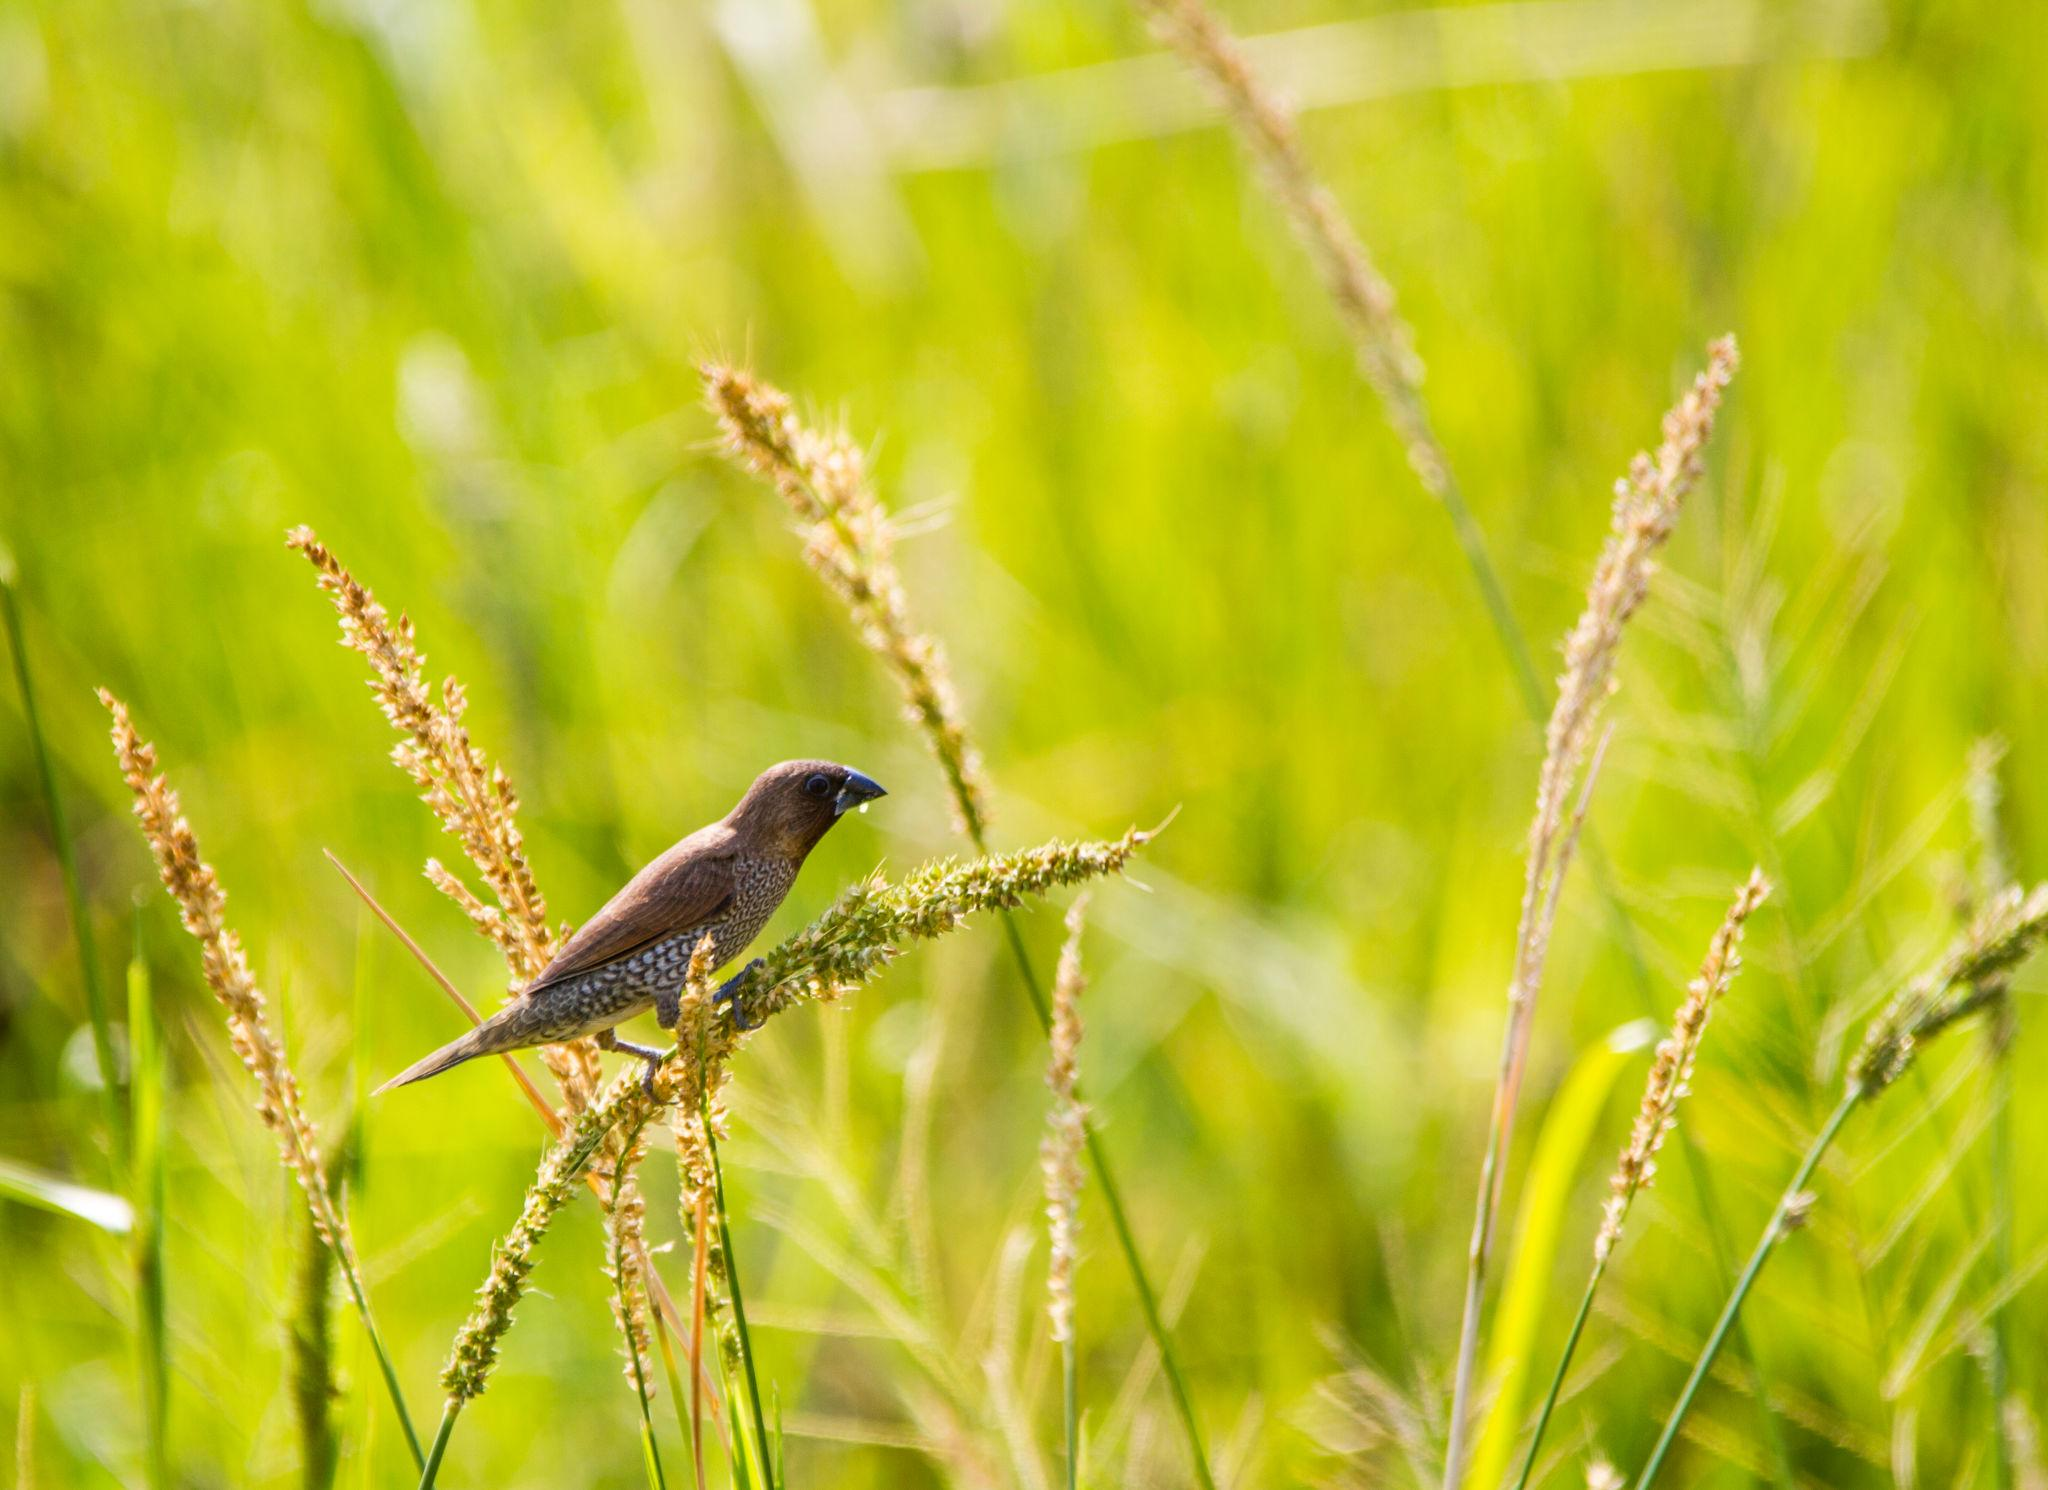


========== DETECTION RESULT ==========
Output: Real
Confidence: 66.11%


In [124]:
import torch
from PIL import Image
from IPython.display import display
from io import BytesIO

# Check whether an image has been uploaded
if not uploader.value:
    print("Please upload an image in Cell 1 first.")

else:
    try:
        # Get uploaded image (supports different ipywidgets versions)
        if isinstance(uploader.value, dict):
            filename, file_info = next(iter(uploader.value.items()))
            image_bytes = bytes(file_info["content"])
        else:
            file_info = uploader.value[0]
            filename = file_info["name"]
            image_bytes = bytes(file_info["content"])

        # Load image
        image = Image.open(BytesIO(image_bytes)).convert("RGB")

        # Display uploaded image
        display(image)

        # Preprocess image
        device = next(model.parameters()).device

        inputs = image_processor(
            images=image,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        # Run prediction
        model.eval()

        with torch.no_grad():
            outputs = model(**inputs)
            probabilities = torch.softmax(outputs.logits, dim=-1)[0]

        # Get predicted class and confidence
        predicted_id = probabilities.argmax().item()

        label = model.config.id2label.get(
            predicted_id, str(predicted_id)
        )

        confidence = probabilities[predicted_id].item() * 100

        # Display only output and confidence
        print("\n========== DETECTION RESULT ==========")
        print(f"Output: {label}")
        print(f"Confidence: {confidence:.2f}%")

    except Exception as e:
        print("Error processing image:", str(e))

In [125]:
import os
import shutil

# Folder containing the complete trained model
SAVE_DIR = "/kaggle/working/ViT_Image_Detector"

os.makedirs(SAVE_DIR, exist_ok=True)

# Save the trained model weights and configuration
model.save_pretrained(SAVE_DIR)

# Save the image processor
image_processor.save_pretrained(SAVE_DIR)

# Display saved files
print("Model saved successfully!")
print("\nFiles saved:")

for file in os.listdir(SAVE_DIR):
    path = os.path.join(SAVE_DIR, file)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"{file}: {size_mb:.2f} MB")

# Create a ZIP file for downloading
ZIP_PATH = shutil.make_archive(
    "/kaggle/working/ViT_Image_Detector",
    "zip",
    root_dir="/kaggle/working",
    base_dir="ViT_Image_Detector"
)

print("\nZIP created:", ZIP_PATH)
print(f"ZIP size: {os.path.getsize(ZIP_PATH) / (1024 * 1024):.2f} MB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!

Files saved:
config.json: 0.00 MB
model.safetensors: 1157.06 MB
preprocessor_config.json: 0.00 MB

ZIP created: /kaggle/working/ViT_Image_Detector.zip
ZIP size: 1075.07 MB


In [130]:
import os
import shutil

SAVE_DIR = "/kaggle/working/ViT_Image_Detector"

ZIP_PATH = shutil.make_archive(
    "/kaggle/working/ViT_Image_Detector",
    "zip",
    root_dir="/kaggle/working",
    base_dir="ViT_Image_Detector"
)

print("ZIP created successfully!")
print(f"Location: {ZIP_PATH}")
print(f"Size: {os.path.getsize(ZIP_PATH) / (1024**3):.2f} GB")

ZIP created successfully!
Location: /kaggle/working/ViT_Image_Detector.zip
Size: 1.05 GB


from IPython.display import FileLink, display
import os

zip_path = "/kaggle/working/ViT_Image_Detector.zip"

if os.path.exists(zip_path):
    print("ZIP found:", os.path.getsize(zip_path) / (1024**3), "GB")
    display(FileLink("ViT_Image_Detector.zip"))
else:
    print("ZIP not found!")